# Force tracking simulation with PD controller

This notebook demonstrates force tracking using a motoneuron pool model with a proportional-derivative (PD) controller. The controller adjusts excitatory drive to match a target force trajectory.

**Key features:**
- Multiple trajectory types (sinusoidal, chirp, trapezoidal)
- PD controller for real-time force tracking
- Muscle force model with twitch dynamics
- Validation of controller performance
---

## 1. Environment setup

### 1.1 Package imports

In [2]:
# Core packages
using Distributions, Random
using Parameters, Match, SymDict

# Data handling
using JLD2, MAT, CSV, DataFrames, Serialization

# Numerical methods
using DSP, Optim, JuMP, Ipopt

# Visualization
using Plots, CairoMakie
using Colors, ColorSchemes

# Python interop and logging
using PyCall
using Wandb, Logging

println("✓ All packages loaded successfully")

┌ Warning: Package Polynomials does not have MakieCore in its dependencies:
│ - If you have Polynomials checked out for development and have
│   added MakieCore as a dependency but haven't updated your primary
│   environment's manifest file, try `Pkg.resolve()`.
│ - Otherwise you may need to report an issue with Polynomials
└ Loading MakieCore into Polynomials from project dependency, future warnings for Polynomials are suppressed.


✓ All packages loaded successfully


### 1.2 Load custom functions

In [2]:
# Define path to custom functions (ADJUST THIS PATH FOR YOUR SYSTEM)
folder_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/utils/functions_run_simulations"

# Load all .jl files from the directory
if isdir(folder_path)
    for file in readdir(folder_path)
        if endswith(file, ".jl")
            include(joinpath(folder_path, file))
            println("✓ Loaded: ", file)
        end
    end
else
    error("Functions directory not found. Please update folder_path variable.")
end

✓ Loaded: calculate_rates_with_timebase.jl
✓ Loaded: conv_spikes_rates.jl
✓ Loaded: creation_model.jl
✓ Loaded: creation_model_controller.jl
✓ Loaded: filter_input.jl
✓ Loaded: plot_MN_trajectory.jl
✓ Loaded: plot_spike_raster.jl
✓ Loaded: run_sim.jl
✓ Loaded: run_sim_noise.jl
✓ Loaded: run_sim_onemn.jl
✓ Loaded: sim_ode_online_control_exp.jl


---

## 2. Model parameters

### 2.1 Load optimized parameters

In [3]:
# Load optimized calcium channel data
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Subjects_optim_process/VthCa_TA_subject1_gamma1.jld2" VthCa_newTA

nr_s = length(VthCa_newTA)  # Number of motoneurons
global flag = false

println("✓ Loaded optimized VthCa data")
println("Number of motoneurons: ", nr_s)

✓ Loaded optimized VthCa data
Number of motoneurons: 181


### 2.2 Morphological and electrical parameters

In [6]:
# Morphological parameters
rheobase_S = LinRange(3.5, 6.5, nr_s) .+ rand(Normal(0.0, 0.05), nr_s)

# Soma dimensions (converted to cm)
rs_S = LinRange(38.75, 41.25, nr_s) ./ 10000
ls_S = LinRange(77.5, 82.5, nr_s) ./ 10000
rms_S = LinRange(1.15, 1.05, nr_s) .* 1000

# Dendrite dimensions (converted to cm)
rd_S = LinRange(20.75, 31.25, nr_s) ./ 10000
ld_S = LinRange(5500.0, 6800.0, nr_s) ./ 10000
rmd_S = LinRange(14.4, 10.70, nr_s) .* 1000

# Maximum conductances (mS/cm²)
max_gna = 30.0
max_gkf_S = ones(nr_s) .* 4.0
max_gks_S = LinRange(16, 25, nr_s)
max_gca_S = LinRange(0.038, 0.029, nr_s)

# Rate constants (ms⁻¹)
αm = ones(nr_s) .* 22.0
βm = ones(nr_s) .* 13.0
αh_S = ones(nr_s) .* 0.5
βh_S = ones(nr_s) .* 4.0
αn_S = ones(nr_s) .* 1.5
βn_S = ones(nr_s) .* 0.1
αq_S = ones(nr_s) .* 1.5
βq_S = LinRange(0.025, 0.038, nr_s)
αp_D = 0.008
βp_D = LinRange(0.014, 0.016, nr_s)

# Voltage thresholds
Vthca_S = VthCa_newTA[1,:]

println("✓ Morphological and electrical parameters defined")

✓ Morphological and electrical parameters defined


### 2.3 Force production parameters

In [8]:
# Twitch force parameters
Apeak_S = LinRange(0.103, 0.123, nr_s)    # Peak twitch force
tpeak_S = LinRange(110.0, 100.0, nr_s)    # Time to peak (ms)
tetanic_S = LinRange(0.393, 0.491, nr_s)  # Tetanic force limit

println("✓ Force production parameters defined")

✓ Force production parameters defined


### 2.4 Simulation parameters

In [9]:
# Neuromodulation and inhibition
γa = 1.0
γh = ones(nr_s)
IF = LinRange(1.0, 1.0, nr_s)  # Inhibition factor (uniform for now)

# Reversal potentials (centered at 0 mV)
EL = 0; ENa = 120; ECa = 140; EK = -10; Ee = 70; Ei = -16

# Synaptic conductances
Ge = 0.6; Gi = 0.5

# Initial conditions
Vd0 = 0.0; Vs0 = 0.0

# Spike parameters
rp = 5.0  # Refractory period (ms)
pd = 1.0  # Pulse duration (ms)

# Time step
const dt = 0.05  # ms
_int(num) = floor(Int, num)

# Physical constants
ri = 70.0  # Intracellular resistivity (Ω⋅cm)
cm = 1.0   # Membrane capacitance (μF/cm²)

println("✓ Simulation parameters defined")

✓ Simulation parameters defined


### 2.5 Compute derived properties

In [10]:
# Preallocate arrays
MN_list = []
Vth_S = zeros(nr_s); gls_S = zeros(nr_s); gld_S = zeros(nr_s)
gc_S = zeros(nr_s); gna_S = zeros(nr_s); gkf_S = zeros(nr_s)
gks_S = zeros(nr_s); gca_S = zeros(nr_s); rn_S = zeros(nr_s)
cs_S = zeros(nr_s); cd_S = zeros(nr_s)

# Compute for each motoneuron
for i in 1:nr_s
    # Leak conductances (μS)
    gls_S[i] = ((2π * rs_S[i] * ls_S[i]) / rms_S[i]) * 1e6
    gld_S[i] = ((2π * rd_S[i] * ld_S[i]) / rmd_S[i]) * 1e6
    
    # Coupling conductance (μS)
    gc_S[i] = (2 / ((ri * ld_S[i] / (π * rd_S[i]^2)) + 
                    (ri * ls_S[i] / (π * rs_S[i]^2)))) * 1e6
    
    # Input resistance (MΩ)
    rn_S[i] = 1 / (gls_S[i] + ((gld_S[i] * gc_S[i]) / (gld_S[i] + gc_S[i])))
    
    # Voltage threshold (mV)
    Vth_S[i] = round(rn_S[i] * rheobase_S[i], digits=2)
    
    # Capacitances (nF)
    cs_S[i] = 2π * ls_S[i] * rs_S[i] * cm * 1e3
    cd_S[i] = 2π * ld_S[i] * rd_S[i] * cm * 1e3
    
    # Ionic conductances (μS)
    gna_S[i] = 2π * ls_S[i] * rs_S[i] * max_gna * 1e3
    gkf_S[i] = 2π * ls_S[i] * rs_S[i] * max_gkf_S[i] * 1e3
    gks_S[i] = 2π * ls_S[i] * rs_S[i] * max_gks_S[i] * 1e3
    gca_S[i] = 2π * ld_S[i] * rd_S[i] * max_gca_S[i] * 1e3
    
    # Create parameter dictionary
    S_MN = Dict(
        :Cs => cs_S[i], :Cd => cd_S[i], :Irh => rheobase_S[i],
        :gc => gc_S[i], :gNa => gna_S[i], :gKs => gks_S[i],
        :gKf => gkf_S[i], :gCa => gca_S[i], :gld => gld_S[i],
        :gls => gls_S[i], :αp => αp_D, :βp => βp_D[i],
        :αq => αq_S[i], :βq => βq_S[i], :αm => αm[i],
        :βm => βm[i], :αh => αh_S[i], :βh => βh_S[i],
        :αn => αn_S[i], :βn => βn_S[i], :Vth => Vth_S[i],
        :VthCa => Vthca_S[i], :Rn => rn_S[i],
        :Tetanic => tetanic_S[i], :Apeak => Apeak_S[i],
        :IF => IF[i], :tpeak => tpeak_S[i], :γh => γh[i],
        "type" => "All Type"
    )
    
    push!(MN_list, S_MN)
end

MNs = MN_list

println("✓ Computed properties for ", nr_s, " motoneurons")

✓ Computed properties for 181 motoneurons


---

## 3. Excitatory input profile

### 3.1 Choose trajectory type

Select one of the following trajectory types by uncommenting the desired section.

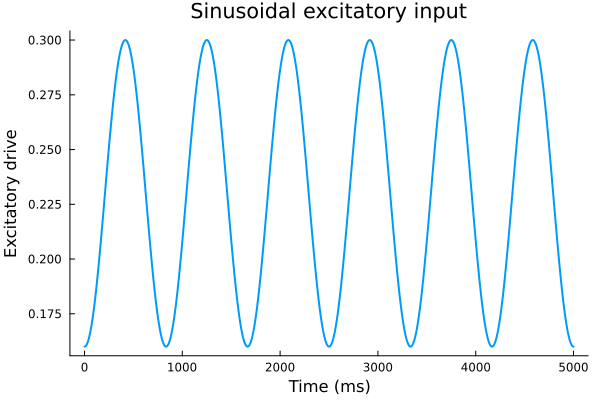

In [11]:
# === SINUSOIDAL (DEFAULT) ===
sim_length = 5000
frequency = 1.2  # Hz
amplitude_min = 0.16
amplitude_max = 0.3
duration = 5.0  # seconds
amplitude = 0.4

t = range(0, stop=duration, length=sim_length)
x_values = 2π * frequency * t
signal = sin.(x_values .- π/2)
signal = (signal .+ 1) / 2
input = signal * (amplitude_max - amplitude_min) .+ amplitude_min

Plots.plot(input, xlabel="Time (ms)", ylabel="Excitatory drive",title="Sinusoidal excitatory input", legend=false, linewidth=2, grid=false)



In [ ]:
# === CHIRP (UNCOMMENT TO USE) ===
# sim_length = 10000
# duration = 10.0
# f0 = 0.0; f1 = 3.0
# amplitude_min = 0.25; amplitude_max = 0.4
# 
# t = range(0, stop=duration, length=sim_length)
# phase = 2π * (f0 .+ (f1 - f0) .* t / duration) .* t
# signal = sin.(phase .- π/2)
# signal = (signal .+ 1) / 2
# input = signal * (amplitude_max - amplitude_min) .+ amplitude_min
# input[1] = amplitude_min
# input[end] = amplitude_min

In [ ]:
# === TRAPEZOIDAL (UNCOMMENT TO USE) ===
# sim_length = 10000
# amplitude = 0.4
# ramp_points = 1000
# plateau_points = 8000
# 
# ramp_up = range(0, amplitude, length=ramp_points)
# plateau = fill(amplitude, plateau_points)
# ramp_down = range(amplitude, 0, length=ramp_points)
# input = vcat(ramp_up, plateau, ramp_down)

### 3.2 Initialize simulation arrays

In [18]:
# Time span
tspan = 0:dt:sim_length
sim_time = _int(sim_length / dt)

# Initial conditions
m = 0.0; h = 1.0; n = 0.0; q = 0.0; p = 0.0
m0 = 0.0; h0 = 1.0; n0 = 0.0; q0 = 0.0; p0 = 0.0
t0 = -1.0; t1 = -1.0; SPIKE0 = 0; SPIKE1 = 0

pool_state_params = fill((m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1), nr_s)

# Storage arrays
spike_arr = zeros(nr_s, sim_time)
vs_arr = zeros(nr_s, sim_time)
pt_arr = zeros(nr_s, sim_time)
mt_arr = zeros(nr_s, sim_time)
ht_arr = zeros(nr_s, sim_time)
nt_arr = zeros(nr_s, sim_time)
qt_arr = zeros(nr_s, sim_time)

# Input arrays
commoninput = input
full_input = zeros(nr_s, sim_length)
independantnoise = zeros(nr_s, sim_length)

# Inhibitory input (constant)
inh_factor = 0.1
inh_input = fill(inh_factor * amplitude, sim_length)

global flag = false

println("✓ Simulation arrays initialized")
println("  Time steps: ", sim_time)
println("  Duration: ", sim_length, " ms")

✓ Simulation arrays initialized
  Time steps: 100000
  Duration: 5000 ms


---

## 4. Target force trajectory

Define the ideal force that the controller will track. Choose one trajectory type (must match the excitatory input profile).

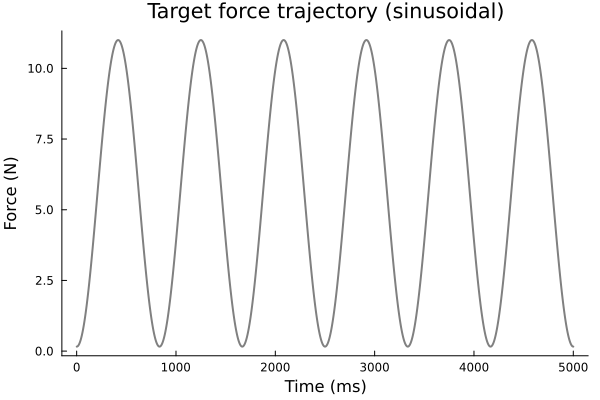

In [19]:
# Sinusoidal force target (DEFAULT)
sim_length = 5000
frequency = 1.2
force_min = 0.16
force_max = 11.0
duration = 5.0

t = range(0, stop=duration, length=sim_length)
x_values = 2π * frequency * t
signal = sin.(x_values .- π/2)
signal = (signal .+ 1) / 2
ideal_force = signal * (force_max - force_min) .+ force_min

Plots.plot(ideal_force, xlabel="Time (ms)", ylabel="Force (N)",title="Target force trajectory (sinusoidal)", legend=false, linewidth=2, grid=false, color=:gray)


In [ ]:
# === CHIRP (UNCOMMENT TO USE) ===
# sim_length = 10000
# duration = 10.0
# f0 = 0.0; f1 = 3.0
# force_min = 0.0; force_max = 12.0
# 
# t = range(0, stop=duration, length=sim_length)
# phase = 2π * (f0 .+ (f1 - f0) .* t / duration) .* t
# signal = sin.(phase .- π/2)
# signal = (signal .+ 1) / 2
# ideal_force = signal * (force_max - force_min) .+ force_min
# ideal_force[1] = force_min
# ideal_force[end] = force_min

In [ ]:
# === TRAPEZOIDAL (UNCOMMENT TO USE) ===
# sim_length = 10000
# force_amplitude = 10.0
# ramp_points = 1000
# plateau_points = 8000
# 
# ramp_up = range(0, force_amplitude, length=ramp_points)
# plateau = fill(force_amplitude, plateau_points)
# ramp_down = range(force_amplitude, 0, length=ramp_points)
# ideal_force = vcat(ramp_up, plateau, ramp_down)

---

## 5. Run PD controller

### 5.1 Controller configuration

The PD controller adjusts excitatory drive based on the error between actual and target force.

**Controller equation:**
```
control_output = kp × error + kd × (derivative of error)
```

**Parameters:**
- **kp:** Proportional gain (response to current error)
- **kd:** Derivative gain (response to rate of change of error)

In [28]:
# PD controller parameters
kp = Float32(2.0)    # Proportional gain
kd = Float32(0.1)    # Derivative gain
dt_control = Float32(0.05)  # Control timestep (ms)

# Number of iterations
max_iterations = 10

println("Controller configuration:")
println("  Proportional gain (kp): ", kp)
println("  Derivative gain (kd): ", kd)
println("  Max iterations: ", max_iterations)
println("\n⚠️  This will take several minutes...")

Controller configuration:
  Proportional gain (kp): 2.0
  Derivative gain (kd): 0.1
  Max iterations: 10

⚠️  This will take several minutes...


### 5.2 Execute controller loop

In [ ]:
# Initialize controller
previous_error = 0.0
input_new = copy(input)
inh_input = fill(0.1 * amplitude, sim_length)

println("\nStarting controller iterations...\n")

for iteration in 1:max_iterations
    println("[Iteration $iteration/$max_iterations]")
    
    # Update input
    commoninput = input_new
    
    # Run simulation
    global spike_array, _ = run_sim()
    
    # Compute muscle force from spike trains
    T = 0.05  # Time step (ms)
    twforce = zeros(size(spike_array))
    
    for i in 1:size(spike_array, 1)
        firings = copy(spike_array) / 0.05
        
        # Second-order filter for twitch dynamics
        a = [1, -2 * exp(-T / tpeak_S[i]), exp(-2 * T / tpeak_S[i])]
        b = [0, Apeak_S[i] * (T^2 / tpeak_S[i]) * exp(1 - T / tpeak_S[i])]
        twforce[i, :] = filt(b, a, firings[i, :])
        
        # Apply tetanic limit
        twforce[i, twforce[i, :] .> tetanic_S[i]] .= tetanic_S[i]
    end
    
    # Total force (sum across all motoneurons)
    trajectory_controlled = sum(twforce, dims=1)
    
    # Downsample for computational efficiency (average every 20 points)
    v = 20
    n = div(size(trajectory_controlled, 2), v)
    new_avg = zeros(n)
    for i in 1:n
        start_idx = (i - 1) * v + 1
        end_idx = i * v
        new_avg[i] = mean(trajectory_controlled[1, start_idx:end_idx])
    end
    
    global trajectory2_controlled = new_avg
    
    # Compute control signal
    for i in 1:size(ideal_force, 1)
        # Error computation
        error = ideal_force[i] - trajectory2_controlled[i]
        
        # Derivative of error
        derivative_error = (error - previous_error) / dt_control
        
        # PD control output
        control_output = kp * error + kd * derivative_error
        
        # Update excitatory drive
        input_new[i] += control_output / 1000
        input_new[i] = clamp(input_new[i], 0.0, 0.6)  # Clamp to physiological range
        
        previous_error = error
    end
    
    # Print progress
    mean_error = mean(abs.(ideal_force .- trajectory2_controlled))
    println("  Mean absolute error: ", round(mean_error, digits=3))
end

println("\n✓ Controller iterations completed!")


Starting controller iterations...

[Iteration 1/10]


---

## 6. Visualization

### 6.1 Excitatory drive comparison

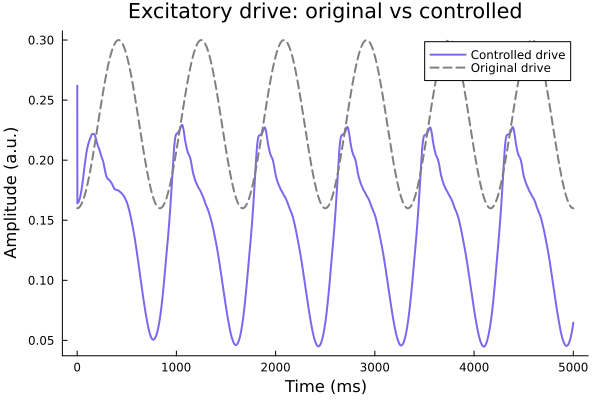

In [24]:
# Plot original vs controlled excitatory drive
Plots.plot(input_new, width=2, color=:mediumslateblue, label="Controlled drive",xlabel="Time (ms)", ylabel="Amplitude (a.u.)",title="Excitatory drive: original vs controlled",grid=false, legend=:topright)
Plots.plot!(input, width=2, color=:gray, label="Original drive", linestyle=:dash)

### 6.2 Force tracking performance

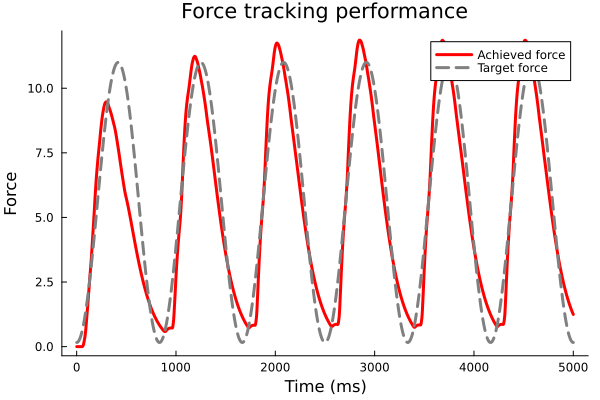

In [27]:
# Plot target vs achieved force
Plots.plot(trajectory2_controlled, width=3, color=:red, label="Achieved force",xlabel="Time (ms)", ylabel="Force",title="Force tracking performance",grid=false, legend=:topright)
Plots.plot!(ideal_force, width=3, color=:gray, label="Target force", linestyle=:dash)

# Compute tracking error metrics
# tracking_error = ideal_force .- trajectory2_controlled
# mae = mean(abs.(tracking_error))
# rmse = sqrt(mean(tracking_error.^2))
# max_error = maximum(abs.(tracking_error))



---

## 7. Save results

In [1]:
# # Define output paths (ADJUST AS NEEDED)
# output_dir = "Data_MN_Model/Data_final/Forcetracking"

# # Create directory if it doesn't exist
# if !isdir(output_dir)
#     mkpath(output_dir)
#     println("Created output directory: ", output_dir)
# end

# # Save results
# JLD2.@save joinpath(output_dir, "controlled_force_sinusoidal.jld2") trajectory2_controlled
# JLD2.@save joinpath(output_dir, "ideal_force_sinusoidal.jld2") ideal_force
# JLD2.@save joinpath(output_dir, "controlled_exc_sinusoidal.jld2") tr_new
# JLD2.@save joinpath(output_dir, "original_exc_sinusoidal.jld2") tr
